In [10]:
from matplotlib import pyplot as plt
import numpy as np
from math import pi

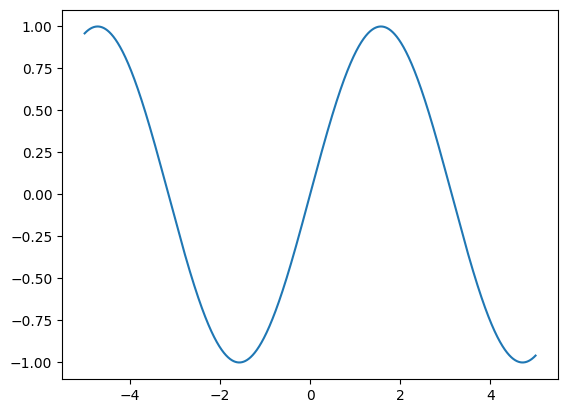

In [2]:
t = np.arange(-5, 5, 0.0001)
y = np.sin(t)

plt.plot(t, y)

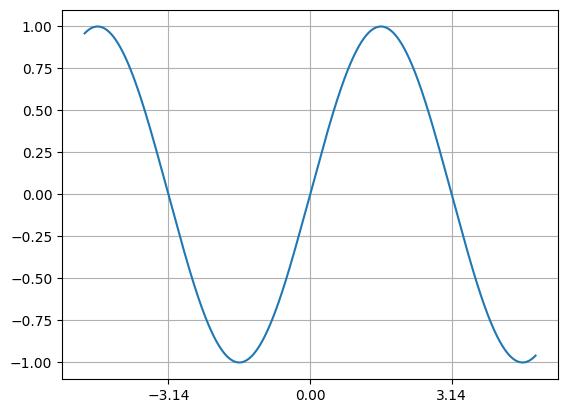

In [3]:
def fsin(x):
  p = ((x/(2*pi)) % 1) * 2 * pi

  p1 = p-pi/2 if p < pi else p - pi - pi/2
  res = 1 - p1*p1/2 + p1**4/26

  # return p1
  return res if p < pi else -res

y = np.zeros(len(t))

for i in range(0, len(t)):
  y[i] = fsin(t[i]);



import matplotlib.pyplot as plt
import matplotlib.ticker as plticker

fig,ax=plt.subplots()

#Spacing between each line

loc = plticker.MultipleLocator(base=3.141)
ax.xaxis.set_major_locator(loc)
# ax.yaxis.set_major_locator(loc)

# Add the grid
ax.grid(which='major', axis='both', linestyle='-')
ax.plot(t, y)

In [4]:
T = 1/44100
t = np.arange(0, T * 1024, T)
len(t)

1024

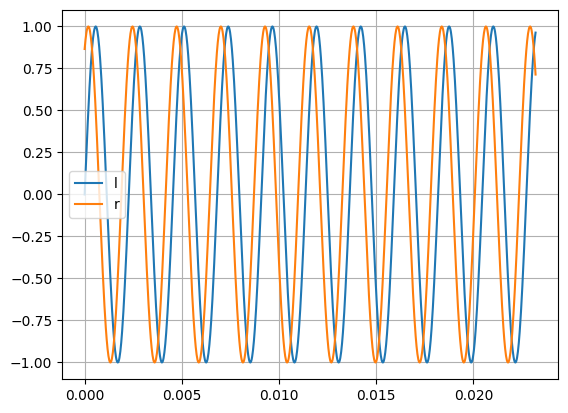

In [5]:
F = 440

yl = np.sin(2 * pi * F * t)
yr = np.sin(2 * pi * F * t + pi/3)

plt.plot(t, yl, label='l')
plt.plot(t, yr, label='r')
plt.grid()
plt.legend()

In [36]:
def process_phase(yl, yr):
  prev_l_sign = None
  prev_r_sign = None
  l_period = None
  l_rise_time = None
  phase = 0
  phase_avg = 0
  phase_smoothing = 0.01
  phase_array = np.zeros(len(yl))
  phase_array_raw = np.zeros(len(yl))

  for i in range(0, len(yl)):
    l = yl[i]
    r = yr[i]

    if prev_l_sign in [-1, 0] and np.sign(l) == 1:
      if l_rise_time is not None:
        l_period = i - l_rise_time

      l_rise_time = i

    if prev_r_sign in [-1, 0] and np.sign(r) == 1:
      delta_samples = i - l_rise_time
      # phase_time = delta_samples * T
      # print(f"{delta_samples}, {phase_time}, {l_period}")
      if l_period is not None:
        phase_new = (delta_samples / l_period) - 0.5
        phase_delta = phase_new - phase
        
        if abs(phase_delta) > 0.7:
          phase_avg += 1 * np.sign(phase_delta)

        phase = phase_new
        # print(phase)

    phase_avg = phase_smoothing * phase + (1-phase_smoothing) * phase_avg
    phase_array[i] = phase_avg
    phase_array_raw[i] = phase

    prev_l_sign = np.sign(l)
    prev_r_sign = np.sign(r)
  
  return phase_array


In [ ]:

phi, phi_r = process_phase(yl, yr)

plt.plot(t, yl, label='l')
plt.plot(t, yr, label='r')
plt.plot(t, phi, label='phi')
plt.grid()
plt.legend()


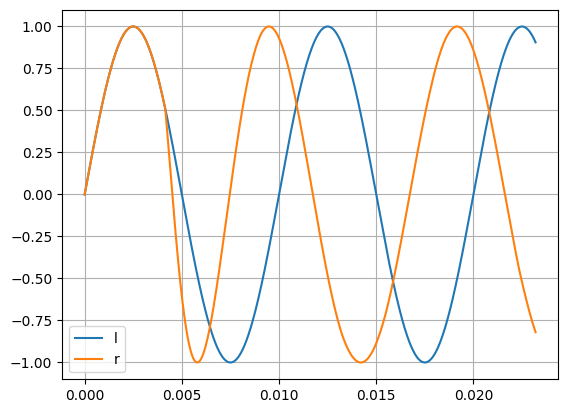

In [7]:
kl = np.sin(2*pi * 100*t)
kr = np.sin(2*pi * (100*t + phi))

plt.plot(t, kl, label='l')
plt.plot(t, kr, label='r')
plt.grid()
plt.legend()

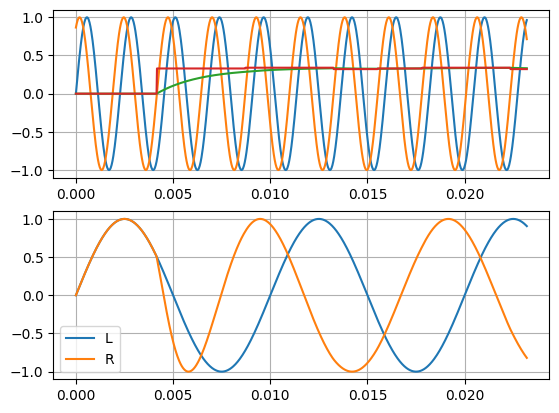

In [8]:
def simulate_phase(t, yl, yr, *, f=100):
  phi, phi_r = process_phase(t, yl, yr)
  kl = np.sin(2*pi * (f*t))
  kr = np.sin(2*pi * (f*t + phi))

  _, axs = plt.subplots(2, 1)

  axs[0].plot(t, yl, label='L')
  axs[0].plot(t, yr, label='R')
  axs[0].plot(t, phi, label='phase')
  axs[0].plot(t, phi_r, label='phase raw')
  axs[0].grid()
  # axs[0].legend()

  axs[1].plot(t, kl, label='L')
  axs[1].plot(t, kr, label='R')
  axs[1].grid()
  axs[1].legend()

simulate_phase(t, yl, yr)

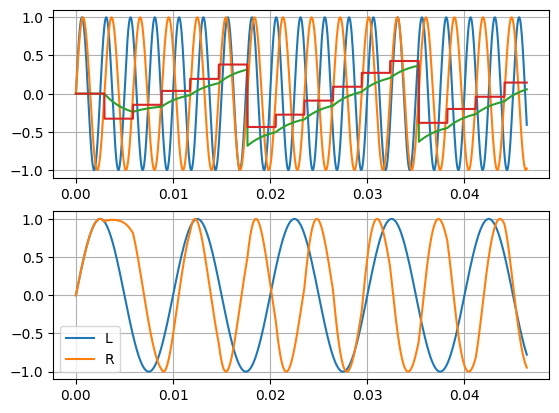

In [9]:
t_1 = np.arange(0, T * 1024*2, T)
yl_1 = np.sin(2*pi*400*t_1)
yr_1 = np.sin(2*pi*340*t_1)

simulate_phase(t_1, yl_1, yr_1)

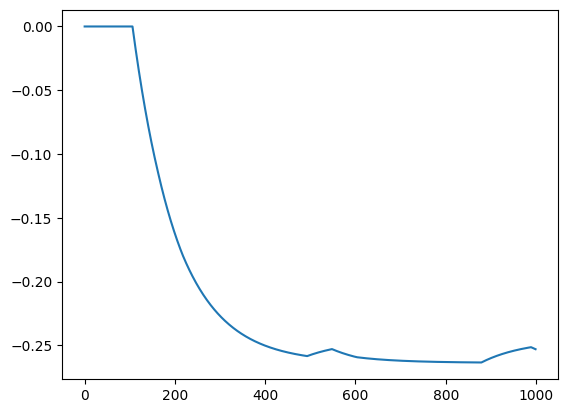

In [46]:
import audio2numpy as a2np
data, sr = a2np.audio_from_file('muq1.mp3')

l_data = data[:, 0]
r_data = data[:, 1]

t_start = 500000
n_samples = 1000
l_data_cut = l_data[t_start:t_start+n_samples]
r_data_cut = r_data[t_start:t_start+n_samples]



ph = process_phase(l_data_cut, r_data_cut)
plt.plot(ph)

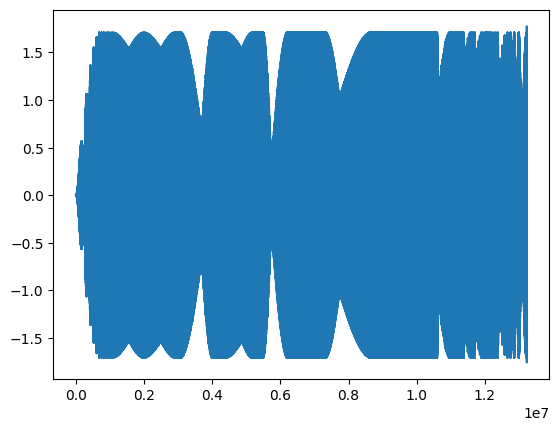

In [47]:
plt.plot(l_data-r_data)